# 01 · Data Prep: Walmart M5, California

**Owner:** Data lead · **Feeds:** every other notebook

This notebook turns the raw Kaggle files into one clean table that every model reads.

**What it does**
1. Loads the three M5 files from the shared Google Drive folder
2. Keeps California's 4 stores (about 12,000 product-store series)
3. Reshapes sales from one column per day to one row per product per day
4. Joins prices and the holiday/SNAP calendar
5. Defines the validation and test windows (shared by everyone)
6. Groups products into fast / medium / slow sellers
7. Saves a 100-product sample for the smoke test
8. Makes the exploration charts for the blog

**Outputs (written to `DATA_DIR` in Drive)**

| File | Contents | Used by |
|---|---|---|
| `ca_sales.parquet` | `unique_id, ds, y` + price and calendar columns | All model notebooks |
| `ca_static.parquet` | One row per series: item, dept, category, store, sales-speed group | Models (static features), evaluation |
| `ca_sample100.parquet` | Same as `ca_sales`, 100 series only | Smoke test |
| `windows.json` | Exact dates of the two validation windows and the test window | All notebooks |
| `figures/*.png` | Exploration charts | Blog, slides |

**Runtime:** standard Colab CPU is fine (no GPU needed). Expect roughly 5–10 minutes and ~6–8 GB of RAM.

## 0 · Settings
Change these if your Drive folder is named differently. Nothing else in the notebook should need editing.

In [3]:
# ---- Settings -------------------------------------------------------------
DRIVE_DIR  = "/content/drive/MyDrive/AML_Term_Project"   # shared team folder
RAW_DIR    = f"{DRIVE_DIR}/raw"       # put the 3 Kaggle CSVs here
DATA_DIR   = f"{DRIVE_DIR}/data"      # outputs from this notebook
FIG_DIR    = f"{DATA_DIR}/figures"

STATE      = "CA"     # California only
HORIZON    = 28       # forecast 28 days ahead
N_VAL      = 2        # number of 28-day validation windows before the test window
SAMPLE_N   = 100      # series in the smoke-test sample
SEED       = 42       # fixed so everyone gets the same sample

RAW_FILES = {
    "sales":    "sales_train_evaluation.csv",   # includes the final 28 days (d_1914–d_1941)
    "calendar": "calendar.csv",
    "prices":   "sell_prices.csv",
}

## 1 · Connect to Google Drive
Before running: create the folder `AML_Term_Project/raw` in the team's shared Drive and upload the three CSVs from
[Kaggle](https://www.kaggle.com/competitions/m5-forecasting-accuracy/data) (accept the competition rules first).
If the folder is shared with you rather than owned by you, right-click it → *Organize → Add shortcut* to put it in *My Drive*.

In [4]:
import os, json
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("Not running in Colab: using the paths in Settings as-is.")

os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

missing = [f for f in RAW_FILES.values() if not os.path.exists(f"{RAW_DIR}/{f}")]
assert not missing, f"Missing in {RAW_DIR}: {missing}"
print("All raw files found.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
All raw files found.


## 2 · Load the raw files

In [5]:
import numpy as np
import pandas as pd

sales_wide = pd.read_csv(f"{RAW_DIR}/{RAW_FILES['sales']}")
calendar   = pd.read_csv(f"{RAW_DIR}/{RAW_FILES['calendar']}")
prices     = pd.read_csv(f"{RAW_DIR}/{RAW_FILES['prices']}")

print("sales   ", sales_wide.shape)
print("calendar", calendar.shape)
print("prices  ", prices.shape)

sales    (30490, 1947)
calendar (1969, 14)
prices   (6841121, 4)


## 3 · Keep California and reshape to long format
The raw file has one row per product-store and one column per day (`d_1` … `d_1941`).
Every forecasting library we use wants one row per product per day, with columns `unique_id`, `ds` (date) and `y` (units sold).

In [6]:
id_cols  = ["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"]
day_cols = [c for c in sales_wide.columns if c.startswith("d_")]

ca_wide = sales_wide[sales_wide["state_id"] == STATE].reset_index(drop=True)
del sales_wide   # free memory
print(f"{STATE}: {len(ca_wide):,} series × {len(day_cols):,} days")

# Static info: one row per series
static = ca_wide[id_cols].copy()
static["unique_id"] = static["id"].str.replace("_evaluation", "", regex=False)
static = static.drop(columns=["id", "state_id"])

# Wide -> long (IDs stored as categories to keep ~23M rows within Colab's memory)
ca_wide["unique_id"] = pd.Categorical(ca_wide["id"].str.replace("_evaluation", "", regex=False))
ca_wide[day_cols] = ca_wide[day_cols].astype("float32")
sales = ca_wide.melt(id_vars=["unique_id"], value_vars=day_cols, var_name="d", value_name="y")
del ca_wide
sales["d"] = sales["d"].astype("category")
print(f"Long format: {len(sales):,} rows")

CA: 12,196 series × 1,941 days
Long format: 23,672,436 rows


## 4 · Join the calendar and prices
- **Calendar** turns `d_1` into a real date and adds events (Super Bowl, Easter, Thanksgiving…) and California's SNAP days.
- **Prices** are weekly, per store and item. A missing price means the product wasn't on sale yet, which is how we detect launch dates.

In [7]:
cal = calendar[["d", "date", "wm_yr_wk", "event_name_1", "event_type_1", "event_name_2", f"snap_{STATE}"]].copy()
cal["ds"] = pd.to_datetime(cal["date"])
cal["is_event"] = (cal["event_name_1"].notna() | cal["event_name_2"].notna()).astype("int8")
cal["event_type"] = cal["event_type_1"].fillna("None")
cal["snap"] = cal[f"snap_{STATE}"].astype("int8")
cal = cal[["d", "ds", "wm_yr_wk", "is_event", "event_type", "snap"]]

sales = sales.merge(cal, on="d", how="left").drop(columns="d")

# Prices: keep California stores only, then attach to each row by store, item and week
item_store = static[["unique_id", "item_id", "store_id"]]
ca_prices = prices[prices["store_id"].isin(static["store_id"].unique())]
ca_prices = ca_prices.merge(item_store, on=["store_id", "item_id"], how="inner")[["unique_id", "wm_yr_wk", "sell_price"]]
sales = sales.merge(ca_prices, on=["unique_id", "wm_yr_wk"], how="left").drop(columns="wm_yr_wk")
del prices, ca_prices
sales["sell_price"] = sales["sell_price"].astype("float32")
print(sales.head())

            unique_id    y         ds  is_event event_type  snap  sell_price
0  HOBBIES_1_001_CA_1  0.0 2011-01-29         0       None     0         NaN
1  HOBBIES_1_002_CA_1  0.0 2011-01-29         0       None     0         NaN
2  HOBBIES_1_003_CA_1  0.0 2011-01-29         0       None     0         NaN
3  HOBBIES_1_004_CA_1  0.0 2011-01-29         0       None     0         NaN
4  HOBBIES_1_005_CA_1  0.0 2011-01-29         0       None     0         NaN


## 5 · Clean up
1. **Drop days before each product launched.** Before its first price appears, a product wasn't on the shelf, so those zeros aren't real demand.
2. **Price features.** `price_ratio` = today's price ÷ the product's average price. Below 1 means it's on discount.
3. **Christmas.** Every store is closed on Dec 25, so sales are near zero. We keep the rows but flag them; none of our evaluation windows include Christmas.

In [8]:
before = len(sales)
first_price_date = sales.loc[sales["sell_price"].notna()].groupby("unique_id")["ds"].min().rename("launch")
sales = sales.merge(first_price_date, on="unique_id", how="left")
sales = sales[sales["ds"] >= sales["launch"]].drop(columns="launch")
print(f"Dropped {before - len(sales):,} pre-launch rows ({(before - len(sales)) / before:.0%})")

# Rare gaps in price after launch: carry the last known price forward
sales = sales.sort_values(["unique_id", "ds"]).reset_index(drop=True)
sales["sell_price"] = sales.groupby("unique_id")["sell_price"].ffill()

sales["price_ratio"] = (sales["sell_price"] / sales.groupby("unique_id")["sell_price"].transform("mean")).astype("float32")
sales["is_christmas"] = ((sales["ds"].dt.month == 12) & (sales["ds"].dt.day == 25)).astype("int8")

for c in ["unique_id", "event_type"]:
    sales[c] = sales[c].astype("category")

assert not sales.duplicated(["unique_id", "ds"]).any(), "Duplicate (unique_id, ds) rows"
print(f"{sales['unique_id'].nunique():,} series, {len(sales):,} rows, {sales['ds'].min().date()} → {sales['ds'].max().date()}")

Dropped 5,113,150 pre-launch rows (22%)
12,196 series, 18,559,286 rows, 2011-01-29 → 2016-05-22


## 6 · Validation and test windows (everyone uses these)
- **Test:** the final 28 days. Nobody tunes on these.
- **Validation:** the two 28-day windows right before the test window. Use these for tuning.

For any window, train on everything **before** its start date and forecast its 28 days.

In [9]:
last_day = sales["ds"].max()
windows = {}
for k in range(N_VAL, -1, -1):          # val_1 (earliest) ... test (latest)
    end   = last_day - pd.Timedelta(days=HORIZON * k)
    start = end - pd.Timedelta(days=HORIZON - 1)
    name  = "test" if k == 0 else f"val_{N_VAL - k + 1}"
    windows[name] = {"start": str(start.date()), "end": str(end.date())}

with open(f"{DATA_DIR}/windows.json", "w") as f:
    json.dump({"horizon": HORIZON, "freq": "D", **windows}, f, indent=2)
pd.DataFrame(windows).T

,start,end
val_1,2016-02-29,2016-03-27
val_2,2016-03-28,2016-04-24
test,2016-04-25,2016-05-22


## 7 · Sales-speed groups (fast / medium / slow)
Each product is grouped by its **average daily sales before the first validation window**, so the groups never peek at evaluation data.
The evaluation notebook breaks results down by these groups and by category.

In [10]:
train_end = pd.Timestamp(windows["val_1"]["start"]) - pd.Timedelta(days=1)
hist = sales[sales["ds"] <= train_end]
speed = hist.groupby("unique_id", observed=True).agg(avg_daily_sales=("y", "mean"),
                                                    zero_share=("y", lambda s: (s == 0).mean()))
speed["sales_speed"] = pd.qcut(speed["avg_daily_sales"].rank(method="first"), 3, labels=["slow", "medium", "fast"])
static = static.merge(speed.reset_index(), on="unique_id", how="left")
static.groupby(["cat_id", "sales_speed"], observed=True).size().unstack()

sales_speed,slow,medium,fast
cat_id,,,
FOODS,963,2100,2685
HOBBIES,1272,631,357
HOUSEHOLD,1830,1334,1024


## 8 · Save everything

In [11]:
sales.to_parquet(f"{DATA_DIR}/ca_sales.parquet", index=False)
static.to_parquet(f"{DATA_DIR}/ca_static.parquet", index=False)

# Smoke-test sample: 100 series, spread evenly across the three categories
rng = np.random.default_rng(SEED)
per_cat = SAMPLE_N // static["cat_id"].nunique()
sample_ids = []
for cat in sorted(static["cat_id"].unique()):
    ids = static.loc[static["cat_id"] == cat, "unique_id"]
    sample_ids += ids.sample(min(per_cat, len(ids)), random_state=SEED).tolist()
sample_ids += static.loc[~static["unique_id"].isin(sample_ids), "unique_id"].sample(SAMPLE_N - len(sample_ids), random_state=SEED).tolist()
sample = sales[sales["unique_id"].isin(sample_ids)].copy()
sample["unique_id"] = sample["unique_id"].cat.remove_unused_categories()
sample.to_parquet(f"{DATA_DIR}/ca_sample100.parquet", index=False)

for f in ["ca_sales.parquet", "ca_static.parquet", "ca_sample100.parquet", "windows.json"]:
    print(f"{f:22s} {os.path.getsize(f'{DATA_DIR}/{f}') / 1e6:8.1f} MB")

ca_sales.parquet           37.6 MB
ca_static.parquet           0.3 MB
ca_sample100.parquet        0.3 MB
windows.json                0.0 MB


## 9 · Exploration charts
Saved to `figures/` for the blog. Each chart has a one-line takeaway to check against what you see.

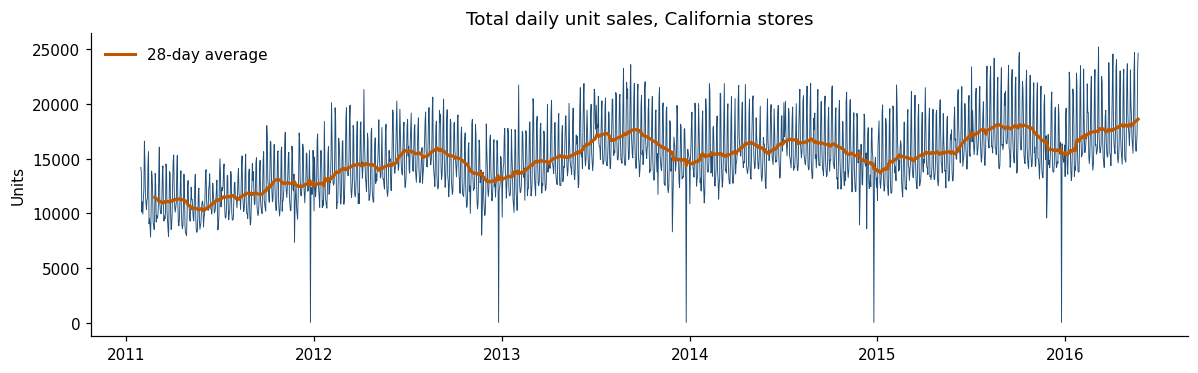

In [12]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def save(fig, name):
    fig.tight_layout()
    fig.savefig(f"{FIG_DIR}/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

# 9a. Total California sales over time (look for: growth, weekly rhythm, Christmas dips)
daily = sales.groupby("ds")["y"].sum()
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(daily.index, daily.values, lw=0.6, color="#1f4e79")
ax.plot(daily.rolling(28).mean(), lw=2, color="#BF5700", label="28-day average")
ax.set_title("Total daily unit sales, California stores"); ax.set_ylabel("Units"); ax.legend(frameon=False)
save(fig, "01_total_sales")

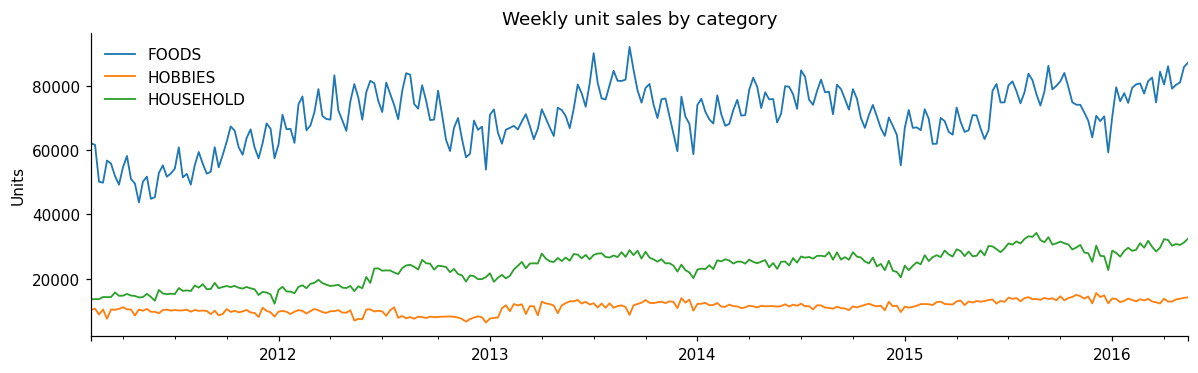

In [13]:
# 9b. Weekly sales by category (look for: Foods dominates volume)
weekly = (sales.merge(static[["unique_id", "cat_id"]], on="unique_id")
               .groupby([pd.Grouper(key="ds", freq="W"), "cat_id"], observed=True)["y"].sum().unstack())
fig, ax = plt.subplots(figsize=(11, 3.5))
weekly.iloc[1:-1].plot(ax=ax, lw=1.2)
ax.set_title("Weekly unit sales by category"); ax.set_ylabel("Units"); ax.set_xlabel(""); ax.legend(frameon=False, title="")
save(fig, "02_sales_by_category")

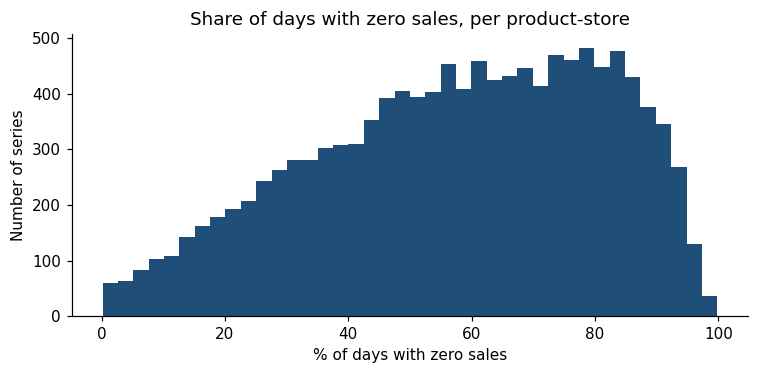

Median series has zero sales on 60% of days


In [14]:
# 9c. How often products sell nothing (look for: most series are zero on many days -> hard to forecast)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(static["zero_share"].dropna() * 100, bins=40, color="#1f4e79")
ax.set_title("Share of days with zero sales, per product-store"); ax.set_xlabel("% of days with zero sales"); ax.set_ylabel("Number of series")
save(fig, "03_zero_sales_share")
print(f"Median series has zero sales on {static['zero_share'].median():.0%} of days")

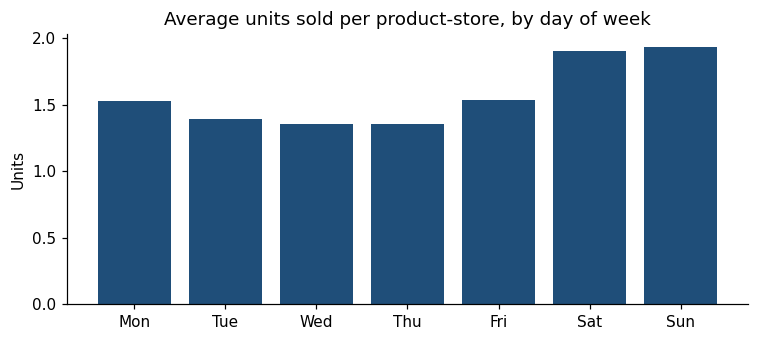

In [15]:
# 9d. Day-of-week pattern (look for: weekend peaks -> why weekly seasonality matters)
dow = sales.groupby(sales["ds"].dt.day_name())["y"].mean().reindex(
    ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(dow.index.str[:3], dow.values, color="#1f4e79")
ax.set_title("Average units sold per product-store, by day of week"); ax.set_ylabel("Units")
save(fig, "04_day_of_week")

In [16]:
# 9e. Sales speed groups (look for: how different 'fast' and 'slow' sellers are)
summary = static.groupby("sales_speed", observed=True).agg(series=("unique_id", "count"),
                                                         avg_daily_sales=("avg_daily_sales", "median"),
                                                         zero_share=("zero_share", "median"))
summary["zero_share"] = (summary["zero_share"] * 100).round(0).astype(int).astype(str) + "%"
summary["avg_daily_sales"] = summary["avg_daily_sales"].round(2)
summary

,series,avg_daily_sales,zero_share
sales_speed,,,
slow,4065,0.23,82%
medium,4065,0.69,60%
fast,4066,2.09,32%


## 10 · Final checks

In [17]:
checks = {
    "series (expect ~12,200)": sales["unique_id"].nunique(),
    "stores (expect 4)": static["store_id"].nunique(),
    "categories (expect 3)": static["cat_id"].nunique(),
    "first date": sales["ds"].min().date(),
    "last date (expect 2016-05-22)": sales["ds"].max().date(),
    "missing y": int(sales["y"].isna().sum()),
    "missing price": int(sales["sell_price"].isna().sum()),
    "sample series": sample["unique_id"].nunique(),
}
for k, v in checks.items():
    print(f"{k:32s} {v}")

series (expect ~12,200)          12196
stores (expect 4)                4
categories (expect 3)            3
first date                       2011-01-29
last date (expect 2016-05-22)    2016-05-22
missing y                        0
missing price                    0
sample series                    100


## How to load this data in the other notebooks
```python
import pandas as pd, json
DATA_DIR = "/content/drive/MyDrive/AML_Term_Project/data"
df      = pd.read_parquet(f"{DATA_DIR}/ca_sales.parquet")      # or ca_sample100.parquet for the smoke test
static  = pd.read_parquet(f"{DATA_DIR}/ca_static.parquet")
windows = json.load(open(f"{DATA_DIR}/windows.json"))
```
**Every model saves forecasts as:** `unique_id, ds, model, window, forecast` → `DATA_DIR/forecasts/<model>_<window>.parquet`